# v.0 Library Usability 

## Preprocessing: from event logs to session sequences

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [15]:
df = pd.read_csv('../../data/ecommerce_clickstream_transactions.csv')
print(df.shape)
df.head()

(74817, 7)


,UserID,SessionID,Timestamp,EventType,ProductID,Amount,Outcome
0,1,1,2024-07-07 18:00:26.959902,page_view,NaN,NaN,NaN
1,1,1,2024-03-05 22:01:00.072000,page_view,NaN,NaN,NaN
2,1,1,2024-03-23 22:08:10.568453,product_view,prod_8199,NaN,NaN
3,1,1,2024-03-12 00:32:05.495638,add_to_cart,prod_4112,NaN,NaN
4,1,1,2024-02-25 22:43:01.318876,add_to_cart,prod_3354,NaN,NaN


### Clean and sort

In [16]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
df = df.dropna(subset=["UserID", "Timestamp", "EventType"]).drop_duplicates()
df["EventType"] = df["EventType"].str.strip().str.lower()
df = df.sort_values(["UserID", "SessionID", "Timestamp"]).reset_index(drop=True)
df["EventType"].value_counts()

EventType
page_view       10819
add_to_cart     10735
product_view    10696
logout          10685
purchase        10682
click           10632
login           10568
Name: count, dtype: int64

In [17]:
df.head()

,UserID,SessionID,Timestamp,EventType,ProductID,Amount,Outcome
0,1,1,2024-01-01 23:09:51.956825,page_view,NaN,NaN,NaN
1,1,1,2024-02-01 05:13:26.944169,add_to_cart,prod_4965,NaN,NaN
2,1,1,2024-02-14 15:41:53.071258,login,NaN,NaN,NaN
3,1,1,2024-02-25 22:43:01.318876,add_to_cart,prod_3354,NaN,NaN
4,1,1,2024-03-05 22:01:00.072000,page_view,NaN,NaN,NaN


In [18]:
g = df.groupby(["UserID", "SessionID"])["Timestamp"]
span_h = (g.max() - g.min()).dt.total_seconds() / 3600
gaps_min = g.diff().dt.total_seconds() / 60
print(f"Median session span: {span_h.median():.2f} hours | Max session span: {span_h.max():.2f} hours")
print(f"Gaps longer than 30 minutes: {(gaps_min > 30).mean() * 100:.2f}%")

Median session span: 3847.17 hours | Max session span: 4920.10 hours
Gaps longer than 30 minutes: 86.55%


#### Define sessions

Choose one. `SESSION_MODE = 'session_id'` uses the given IDs; `'inactivity'` starts a new session after 30 min of silence per user.

In [19]:
SESSION_MODE = "session_id"   # or "inactivity"
GAP_MIN = 30

if SESSION_MODE == "session_id":
    df["session_key"] = df.groupby(["UserID", "SessionID"]).ngroup()
else:
    df = df.sort_values(["UserID", "Timestamp"])
    new = df.groupby("UserID")["Timestamp"].diff().gt(pd.Timedelta(minutes=GAP_MIN))
    new |= df["UserID"].ne(df["UserID"].shift())
    df["session_key"] = new.cumsum()

#### Build sequences and filter by length

In [20]:
df = df.sort_values(["session_key", "Timestamp"])
sessions = (df.groupby("session_key")
              .agg(user=("UserID", "first"),
                   events=("EventType", list),
                   outcome=("Outcome", lambda s: s.dropna().iloc[-1] if s.notna().any() else None),
                   total_amount=("Amount", "sum")))
sessions["n_events"] = sessions["events"].str.len()

hi = np.percentile(sessions["n_events"], 99)
sessions = sessions[(sessions["n_events"] >= 2) & (sessions["n_events"] <= hi)]

sequences = sessions["events"].tolist()   # list[list[str]] -> input for Levenshtein
print(len(sequences), "sessions")
sessions.head()

10000 sessions


,user,events,outcome,total_amount,n_events
session_key,,,,,
0,1,"[page_view, add_to_cart, login, add_to_cart, p...",None,0.000000,9
1,1,"[page_view, page_view, logout, product_view, c...",None,0.000000,6
2,1,"[page_view, login, add_to_cart, click, add_to_...",purchase,72.913619,9
3,1,"[add_to_cart, add_to_cart, login, page_view, a...",purchase,7.677938,10
4,1,"[logout, purchase, purchase, product_view, log...",purchase,998.570616,9


## Testing `BaselineAligner` (Stage 1: Levenshtein distance matrix)

### 0. Import the library
Install once from a terminal (folder containing `pyproject.toml`): `pip install -e .`

In [21]:
import sys
import time
from pathlib import Path

# Add v0.2/ root to sys.path so `journey_analyzer` imports cleanly from notebooks/
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Top-level API import (tests journey_analyzer/__init__.py)
from journey_analyzer import BaselineAligner

# Sub-package pure function imports (tests journey_analyzer/alignment/__init__.py)
from journey_analyzer.alignment import (
    assign_stages,
    levenshtein_distance,
    normalized_levenshtein_distance,
    weighted_levenshtein_distance,
)

print("Successfully imported BaselineAligner and distance functions!")

Successfully imported BaselineAligner and distance functions!


In [22]:
import time
from journey_analyzer import BaselineAligner
from journey_analyzer.alignment import levenshtein_distance, normalized_levenshtein_distance

### 1. Sanity check on hand-made journeys
Before trusting 10,000 sessions we check the metric on cases where we know the answer.

In [23]:
a = ["login", "product_view", "add_to_cart", "purchase"]
b = ["login", "product_view", "purchase"]                  # a without 'add_to_cart'
c = ["logout", "click", "click", "page_view"]              # nothing in common with a

print("a vs a :", levenshtein_distance(a, a))                    # 0 -> identical
print("a vs b :", levenshtein_distance(a, b))                    # 1 -> one deletion
print("a vs c :", levenshtein_distance(a, c))                    # 4 -> four substitutions
print("a vs c normalized:", normalized_levenshtein_distance(a, c))  # 1.0 -> completely different

a vs a : 0.0
a vs b : 1.0
a vs c : 4.0
a vs c normalized: 1.0


### 2. Distance matrix on a random sample of 500 sessions (Experiment 1 scale)
We sample randomly (not `sequences[:500]`), because sessions are stored user by user and the first rows would all belong to the same few users.

In [24]:
rng = np.random.default_rng(42)
idx = rng.choice(len(sequences), size=500, replace=False)
sample = [sequences[i] for i in idx]

aligner = BaselineAligner(metric="levenshtein")
t0 = time.perf_counter()
D = aligner.fit_distance_matrix(sample)
print(f"Matrix {D.shape} computed in {time.perf_counter() - t0:.1f} s")

Matrix (500, 500) computed in 2.0 s


### 3. Are the matrix properties right?

In [25]:
print("symmetric       :", np.allclose(D, D.T))
print("zero diagonal   :", bool(np.all(np.diag(D) == 0)))
print("non-negative    :", bool(D.min() >= 0))

upper = D[np.triu_indices_from(D, k=1)]          # each pair counted once
print(f"pairs: {len(upper):,} | min {upper.min():.0f} | mean {upper.mean():.2f} | max {upper.max():.0f}")
print("read-only matrix:", not D.flags.writeable)

symmetric       : True
zero diagonal   : True
non-negative    : True
pairs: 124,750 | min 0 | mean 6.55 | max 10
read-only matrix: True


### 4. Distribution of distances
If the data had real behavioural groups we would expect several bumps (small distances inside a group, large between groups).

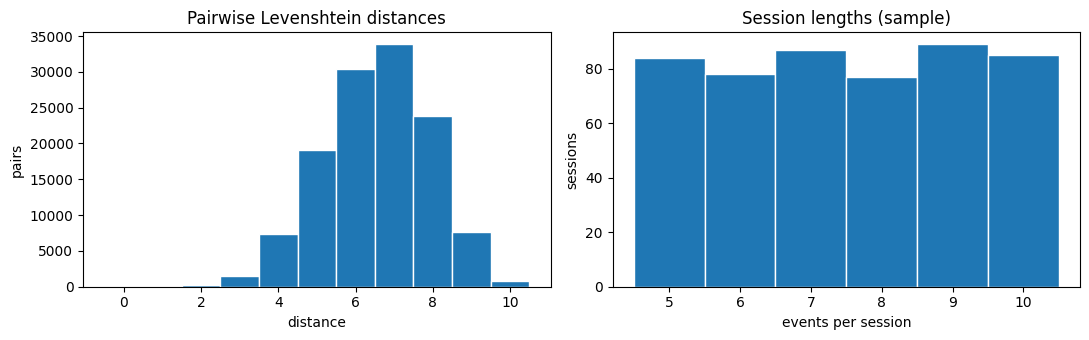

In [26]:
lens = np.array([len(s) for s in sample])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(upper, bins=np.arange(upper.min(), upper.max() + 2) - 0.5, edgecolor="white")
ax[0].set(title="Pairwise Levenshtein distances", xlabel="distance", ylabel="pairs")
ax[1].hist(lens, bins=np.arange(lens.min(), lens.max() + 2) - 0.5, edgecolor="white")
ax[1].set(title="Session lengths (sample)", xlabel="events per session", ylabel="sessions")
plt.tight_layout(); plt.show()

### 5. Look at actual journeys: closest vs. farthest pair

In [27]:
M = D.copy(); np.fill_diagonal(M, np.inf)
i, j = np.unravel_index(M.argmin(), M.shape)
print("MOST SIMILAR pair, distance", D[i, j]); print("  ", sample[i]); print("  ", sample[j])

M = D.copy(); np.fill_diagonal(M, -np.inf)
i, j = np.unravel_index(M.argmax(), M.shape)
print("\nMOST DIFFERENT pair, distance", D[i, j]); print("  ", sample[i]); print("  ", sample[j])

MOST SIMILAR pair, distance 0.0
   ['add_to_cart', 'login', 'purchase', 'purchase', 'page_view']
   ['add_to_cart', 'login', 'purchase', 'purchase', 'page_view']

MOST DIFFERENT pair, distance 10.0
   ['logout', 'click', 'login', 'purchase', 'add_to_cart', 'login']
   ['product_view', 'page_view', 'purchase', 'page_view', 'product_view', 'product_view', 'product_view', 'product_view', 'product_view', 'add_to_cart']


### 6. Weighted metric (stage-aware)
Stages follow Kinjo (2025): pre-purchase, purchase, post-purchase. Here the purchase stage counts 3x.

In [28]:
STAGES = {"login": "pre", "page_view": "pre", "product_view": "pre", "click": "pre",
          "add_to_cart": "pre", "purchase": "purchase", "logout": "post"}

aligner_w = BaselineAligner("weighted", stage_weights={"purchase": 3.0}, event_to_stage=STAGES)
D_w = aligner_w.fit_distance_matrix(sample)
upper_w = D_w[np.triu_indices_from(D_w, k=1)]

print("Spearman correlation, plain vs weighted:",
      round(pd.Series(upper).corr(pd.Series(upper_w), method="spearman"), 3))
print(f"mean plain {upper.mean():.2f} | mean weighted {upper_w.mean():.2f}")

Spearman correlation, plain vs weighted: 0.497
mean plain 6.55 | mean weighted 8.86


### 7. Runtime growth: is it really quadratic?

seconds: [0.02, 0.07, 0.28, 1.23] | estimated exponent: 2.02
Extrapolation to all 10,000 sessions: ~0.2 hours


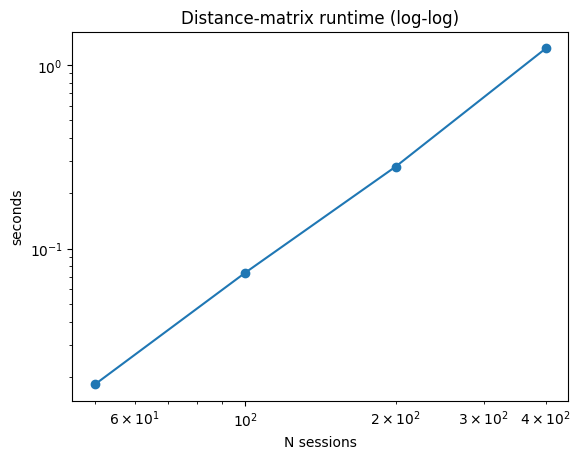

In [29]:
sizes = [50, 100, 200, 400]
times = []
for n in sizes:
    t0 = time.perf_counter()
    BaselineAligner().fit_distance_matrix(sample[:n])
    times.append(time.perf_counter() - t0)

slope = np.polyfit(np.log(sizes), np.log(times), 1)[0]     # slope of log-log line = exponent
print("seconds:", [round(t, 2) for t in times], "| estimated exponent:", round(slope, 2))

n_all = len(sequences)
est_h = times[-1] * (n_all / sizes[-1]) ** 2 / 3600
print(f"Extrapolation to all {n_all:,} sessions: ~{est_h:.1f} hours")

plt.loglog(sizes, times, "o-"); plt.xlabel("N sessions"); plt.ylabel("seconds")
plt.title("Distance-matrix runtime (log-log)"); plt.show()

### 8. Memory guard
The aligner refuses to allocate a matrix above `max_matrix_gb`, before it starts computing.

In [30]:
try:
    BaselineAligner(max_matrix_gb=0.1).fit_distance_matrix(sequences)   # 10,000 x 10,000 float32 = 0.4 GB
except MemoryError as e:
    print("MemoryError:", e)

MemoryError: A 10000 x 10000 float32 distance matrix needs ~0.4 GB (limit 0.1 GB). Use a subsample or switch to the O(N) methods (k-grams / LDA / SBERT).
